In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from sklearn.metrics import confusion_matrix

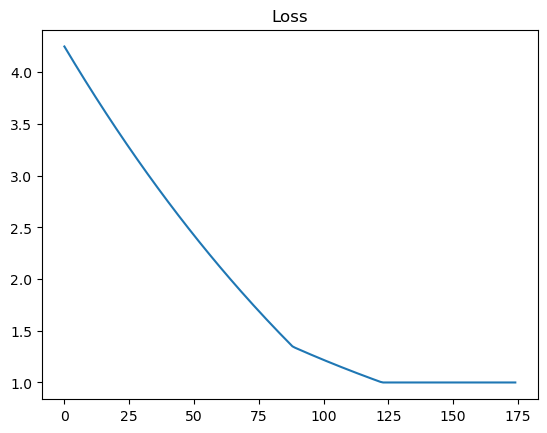

In [2]:
# Problem 3
mu = 1e-3
T = 175
x = [0.5, 0.5]

f = lambda x: (x[0] - 2)**2 + (x[1] - 2)**2 - x[0] * x[1]
grad = lambda x: np.array([4 * (x[0] - 2) - x[1], 4 * (x[1] - 2) + x[0]])
update = lambda x: x - mu * grad(x)
project = lambda x: [min(max(x[0], 0), 1), min(max(x[1], 0), 1)]

losses = np.array([])
for t in range(T):
    losses = np.append(losses, f(x))
    x = project(update(x))
    
plt.plot(losses)
plt.title('Loss')
plt.show()

In [3]:
train_data = pd.read_csv('data/mnist_train.csv', header=None).rename(columns={0: 'label'})
test_data = pd.read_csv('data/mnist_test.csv', header=None).rename(columns={0: 'label'})

In [4]:
def filter_df(df, label_map):
    nums_df = [(df.query(f'label == {num}').iloc[:500] / 255)
               .assign(label=[label] * 500) 
               for label, num in label_map.items()]
    return pd.concat(nums_df).reset_index(drop=True)
    
def loss_fn(w, X, Y):
    log_reg = lambda w, x, y: np.log(1 + np.exp(-y * np.dot(x, w)))
    return np.mean([log_reg(w, x, y) for x, y in zip(X, Y)])

def grad(w, X, Y):
    sigmoid = lambda z: 1 / (1 + np.exp(-np.clip(z, -500, 500)))
    log_reg_grad = lambda w, x, y: sigmoid(-y * np.dot(x, w)) * (-y * x)
    return np.mean([log_reg_grad(w, x, y) for x, y in zip(X, Y)], axis=0)

def train(w, X, Y, L=2, mu=1e-4, T=10_000, stop=1e-2, step_direction=lambda x: x):
    losses = np.array([])

    for t in tqdm(np.arange(T)):
        loss = loss_fn(w, X, Y)
        losses = np.append(losses, loss)
        
        gradient = grad(w, X, Y)
        w = w - mu * step_direction(gradient)
        
        norm = np.linalg.norm(gradient, L)
        tqdm.write(f'Step: {t+1}, Loss: {loss}, Grad: {norm}', end='\r')
        if norm < stop: break
        
    plt.plot(losses)
    plt.title('Training Loss')
    plt.show()
    return w

In [5]:
label_map = {-1: 4, 1: 9}
train_df = filter_df(train_data, label_map)
test_df = filter_df(test_data, label_map)

X = train_df.iloc[:, 1:].to_numpy()
Y = train_df.iloc[:, 0].to_numpy()
w_0 = np.zeros(X.shape[1])

In [6]:
# Problem 4a
p = lambda grad: np.sign(grad) * np.sum(np.abs(grad))
w_inf = train(w_0, X, Y, L=np.inf, mu=1e-3, stop=1e-4, T=1_000, step_direction=p)

  0%|          | 0/1000 [00:00<?, ?it/s]

KeyboardInterrupt: 

  0%|          | 0/1000 [00:00<?, ?it/s]

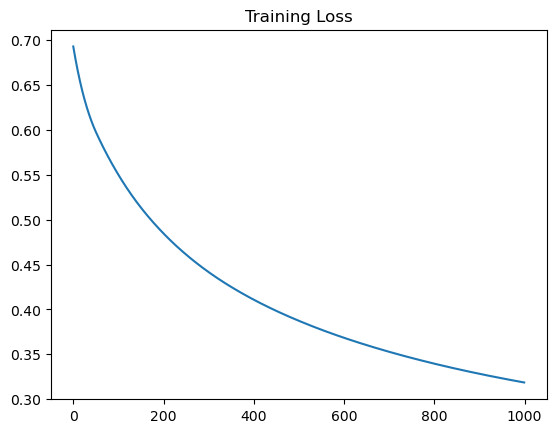

In [ ]:
# Problem 4b / 4d
coords = np.zeros(X.shape[1])

def p(grad):
    j = np.argmax(np.abs(grad))
    direction = np.zeros_like(grad)
    direction[j] = np.sign(grad[j]) * np.abs(grad[j])
    coords[j] += 1
    return direction

w_1 = train(w_0, X, Y, L=1, mu=1e-1, T=1_000, step_direction=p)

  0%|          | 0/1000 [00:00<?, ?it/s]

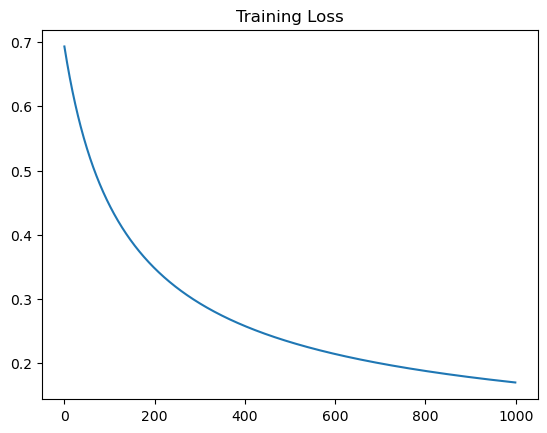

In [ ]:
w_2 = train(w_0, X, Y, mu=1e-2, T=1_000)

In [ ]:
def predict_one(w, x, show=False):
    pred = np.sign(np.dot(x, w))
    if show:
        plt.imshow(x.reshape(28, 28), cmap='gray')
        plt.title(f'Prediction: {label_map[pred]}')
        plt.axis('off')
        plt.show()
    return pred

def display_confusion_matrix(w, df):
    features = df.iloc[:, 1:].to_numpy()
    labels = df.iloc[:, 0].to_numpy()
    predictions = [predict_one(w, x) for x in features]

    cm = confusion_matrix(labels, predictions)
    cm_percentages = cm / cm.sum(axis=1, keepdims=True) * 100

    plt.imshow(cm, cmap='Blues')
    plt.title('Confusion Matrix')

    for i, j in np.ndindex(cm.shape):
        plt.text(j, i, f'{cm[i, j]}\n({cm_percentages[i, j]:.1f}%)', 
            ha='center', va='center', 
            color='white' if cm_percentages[i, j] > 50 else 'black')

    plt.colorbar()
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.xticks([0, 1])
    plt.yticks([0, 1])
    plt.show()
    
    accuracy = (labels == predictions).mean()
    return accuracy

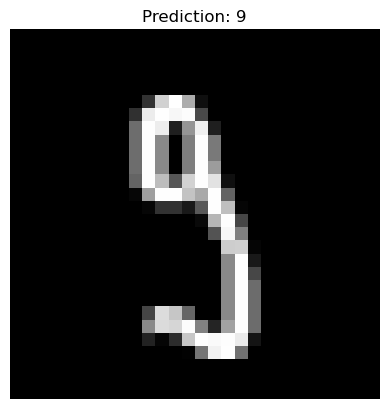

np.float64(1.0)

In [ ]:
predict_one(w_2, train_df.sample(1).iloc[0, 1:].to_numpy(), show=True)

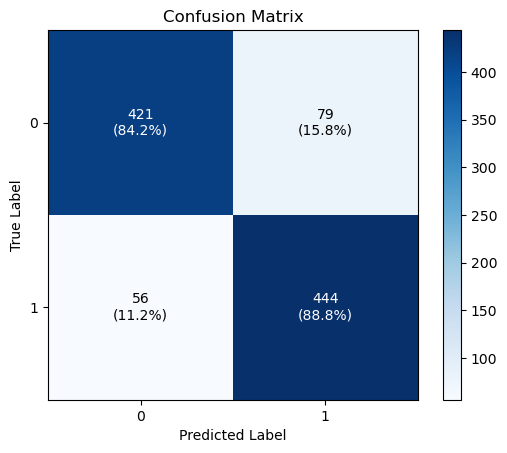

np.float64(0.865)

In [ ]:
display_confusion_matrix(w_1, test_df)

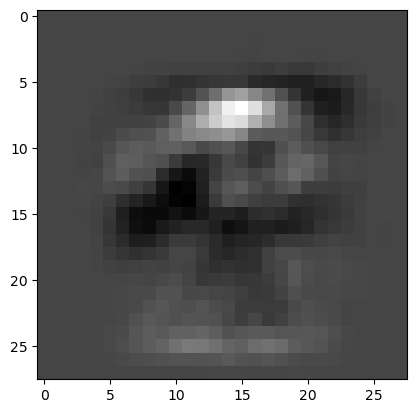

In [ ]:
plt.imshow(w_2.reshape(28, 28), cmap='gray')
plt.show()